# 🎓 Data Analytics in Student Life
### *What really affects a student's final grade? A real-data case study*

**Level:** First-year students (beginner friendly)  
**Tools:** Python, pandas, NumPy, Matplotlib, Seaborn, scikit-learn  
**Dataset:** *Student Performance* (UCI Machine Learning Repository), real records of **395 students** in a Mathematics course, collected through school reports and questionnaires (Cortez & Silva, 2008).

---

## 📌 Why this notebook?
Schools, universities and learning apps use data every day to support students. Here we follow the same professional workflow:

| Step | Question we ask | Real-life example |
|---|---|---|
| 1. Collect | What data do we have? | School records + student survey |
| 2. Clean | Is the data correct? | Checking missing values and odd entries |
| 3. Explore | What does the data look like? | Averages and charts |
| 4. Analyse | What is linked to grades? | Study time, past failures, absences |
| 5. Predict | Can we estimate a grade early? | Early-warning system for at-risk students |
| 6. Decide | What should students and schools do? | Mentoring, timetable support |

> **About the data:** the students are in secondary school (ages 15 to 22), not first-year university. The habits studied (study time, absences, social life) are the same ones you face in college, so the lessons carry over. Grades are out of **20**, and **10 or above is a pass**.

## 1️⃣ Import Libraries
A **library** is a ready-made toolbox of code. We import them once at the top.

In [31]:
import numpy as np                      # NumPy: fast maths on numbers
import pandas as pd                     # pandas: tables of data (called DataFrames)
import matplotlib.pyplot as plt         # Matplotlib: basic charts
import seaborn as sns                   # Seaborn: prettier statistical charts
from sklearn.linear_model import LinearRegression          # A simple prediction model
from sklearn.model_selection import train_test_split       # Splits data into practice part and test part
from sklearn.metrics import r2_score, mean_absolute_error  # Scores that tell us how good predictions are

sns.set_theme(style="whitegrid")        # Apply a clean chart style
pd.set_option("display.max_columns", None)  # Show all columns when printing tables
print("Libraries loaded successfully ✅")  # Confirmation message

Libraries loaded successfully ✅


## 2️⃣ Load the Dataset (from the internet)
We read the file directly from an online link. If you have no internet, download `student-mat.csv` and keep it in the same folder as this notebook; the code falls back to it automatically.

**Important:** this file uses a **semicolon (`;`)** instead of a comma between values, so we tell pandas with `sep=";"`.

**Columns we will use**

| Column | Meaning |
|---|---|
| `sex` | Student's sex (F/M) |
| `age` | Age in years (15 to 22) |
| `studytime` | Weekly study time: 1 = under 2h, 2 = 2 to 5h, 3 = 5 to 10h, 4 = over 10h |
| `failures` | Number of past class failures (0 to 3) |
| `absences` | Number of school absences |
| `Medu`, `Fedu` | Mother's / father's education (0 = none ... 4 = higher education) |
| `goout` | Going out with friends (1 = very low ... 5 = very high) |
| `Walc` | Weekend alcohol use (1 = very low ... 5 = very high) |
| `higher` | Wants to take higher education? (yes/no) |
| `internet` | Internet access at home? (yes/no) |
| `romantic` | In a romantic relationship? (yes/no) |
| `G1`, `G2` | Grades in 1st and 2nd period (0 to 20) |
| `G3` | **Final grade (0 to 20)**, our main target |

In [32]:
URL = "https://raw.githubusercontent.com/Rohith04MVK/Student-Score-ML/main/student-mat.csv"  # Online location of the CSV file

try:                                              # Try the online link first
    df = pd.read_csv(URL, sep=";")                # Read the CSV; sep=";" because values are separated by semicolons
    print("Loaded from the internet ✅")           # Tell the user it worked
except Exception:                                 # If there is no internet or the link fails...
    df = pd.read_csv("student-mat.csv", sep=";")  # ...read the local copy instead
    print("Loaded from local file ✅")             # Tell the user which source was used

print("Rows and columns:", df.shape)              # shape gives (number of students, number of columns)

Loaded from the internet ✅
Rows and columns: (395, 33)


## 3️⃣ First Look at the Data
Always **look** at your data before analysing it, like reading the question paper before writing the answer.

In [33]:
df.head()          # Show the first 5 students (rows) of the table

,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,reason,guardian,traveltime,studytime,failures,schoolsup,famsup,paid,activities,nursery,higher,internet,romantic,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,course,mother,2,2,0,yes,no,no,no,yes,yes,no,no,4,3,4,1,1,3,6,5,6,6
1,GP,F,17,U,GT3,T,1,1,at_home,other,course,father,1,2,0,no,yes,no,no,no,yes,yes,no,5,3,3,1,1,3,4,5,5,6
2,GP,F,15,U,LE3,T,1,1,at_home,other,other,mother,1,2,3,yes,no,yes,no,yes,yes,yes,no,4,3,2,2,3,3,10,7,8,10
3,GP,F,15,U,GT3,T,4,2,health,services,home,mother,1,3,0,no,yes,yes,yes,yes,yes,yes,yes,3,2,2,1,1,5,2,15,14,15
4,GP,F,16,U,GT3,T,3,3,other,other,home,father,1,2,0,no,yes,yes,no,yes,yes,no,no,4,3,2,1,2,5,4,6,10,10


In [34]:
df.info()          # Shows each column's name, data type and number of non-empty values

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 395 entries, 0 to 394
Data columns (total 33 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   school      395 non-null    object
 1   sex         395 non-null    object
 2   age         395 non-null    int64 
 3   address     395 non-null    object
 4   famsize     395 non-null    object
 5   Pstatus     395 non-null    object
 6   Medu        395 non-null    int64 
 7   Fedu        395 non-null    int64 
 8   Mjob        395 non-null    object
 9   Fjob        395 non-null    object
 10  reason      395 non-null    object
 11  guardian    395 non-null    object
 12  traveltime  395 non-null    int64 
 13  studytime   395 non-null    int64 
 14  failures    395 non-null    int64 
 15  schoolsup   395 non-null    object
 16  famsup      395 non-null    object
 17  paid        395 non-null    object
 18  activities  395 non-null    object
 19  nursery     395 non-null    object
 20  higher    

In [35]:
key_cols = ["age", "studytime", "failures", "absences", "G1", "G2", "G3"]  # Pick a few important numeric columns
df[key_cols].describe().round(2)                                          # Summary statistics for them

,age,studytime,failures,absences,G1,G2,G3
count,395.00,395.00,395.00,395.00,395.00,395.00,395.00
mean,16.70,2.04,0.33,5.71,10.91,10.71,10.42
std,1.28,0.84,0.74,8.00,3.32,3.76,4.58
min,15.00,1.00,0.00,0.00,3.00,0.00,0.00
25%,16.00,1.00,0.00,0.00,8.00,9.00,8.00
50%,17.00,2.00,0.00,4.00,11.00,11.00,11.00
75%,18.00,2.00,0.00,8.00,13.00,13.00,14.00
max,22.00,4.00,3.00,75.00,19.00,19.00,20.00


**How to read `describe()`:**  
- `mean` = average, `std` = how spread out the values are  
- `50%` = the **median** (the middle student)  
- `min` / `max` = lowest and highest values  

Notice that the average final grade (`G3`) is about 10.4 out of 20, so a typical student is right around the pass mark.

## 4️⃣ Data Cleaning and Preparation
**Data cleaning** means checking and fixing problems *before* analysis so our conclusions are trustworthy.

In [36]:
print("Missing values in total:", df.isnull().sum().sum())   # Count empty cells in the whole table
print("Duplicate rows:", df.duplicated().sum())              # Count students that appear twice

Missing values in total: 0
Duplicate rows: 0


✅ This dataset has no missing values and no duplicates, which is **rare** in real life. But "no empty cells" does **not** mean "no problems". We will find a hidden problem in Insight 4.

Now we create some helpful new columns to make analysis easier.

In [37]:
df["result"] = np.where(df["G3"] >= 10, "Pass", "Fail")       # New column: Pass if final grade is 10 or more, else Fail

study_labels = {1: "<2h", 2: "2-5h", 3: "5-10h", 4: ">10h"}   # Dictionary that turns study-time codes into readable text
df["study_band"] = df["studytime"].map(study_labels)          # New column with readable weekly study time

df["higher_n"] = (df["higher"] == "yes").astype(int)          # Turn yes/no into 1/0 so the model can use it
df["internet_n"] = (df["internet"] == "yes").astype(int)      # Same for internet access

df[["studytime", "study_band", "G3", "result"]].head()        # Check that the new columns look right

,studytime,study_band,G3,result
0,2,2-5h,6,Fail
1,2,2-5h,6,Fail
2,2,2-5h,10,Pass
3,3,5-10h,15,Pass
4,2,2-5h,10,Pass


## 5️⃣ Exploratory Data Analysis (EDA)
EDA means asking questions and answering them with charts and numbers. Each question is one a school counsellor would ask.

### 📊 Insight 1: How are final grades distributed?

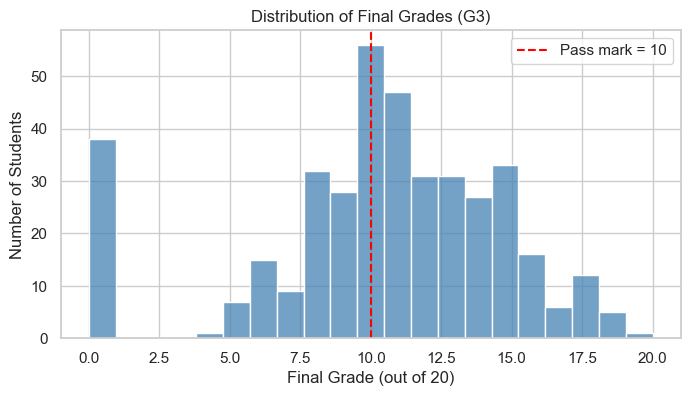

Pass rate: 67.1 %
Students with grade 0: 38


In [38]:
plt.figure(figsize=(8, 4))                                            # Create a blank chart 8 wide, 4 tall
sns.histplot(df["G3"], bins=21, color="steelblue")                    # Histogram: bar height = number of students with that grade
plt.axvline(10, color="red", linestyle="--", label="Pass mark = 10")  # Red dashed line at the pass mark
plt.title("Distribution of Final Grades (G3)")                        # Chart title
plt.xlabel("Final Grade (out of 20)")                                 # x-axis label
plt.ylabel("Number of Students")                                      # y-axis label
plt.legend()                                                          # Show the red line's label
plt.show()                                                            # Display the chart

print("Pass rate:", round((df["G3"] >= 10).mean() * 100, 1), "%")     # Share of students at or above 10
print("Students with grade 0:", (df["G3"] == 0).sum())                # Count of students with a final grade of exactly 0

**Meaning:** About two-thirds of students pass. Look at the **tall bar at 0**: 38 students have a final grade of exactly zero. Keep this in mind, because it explains a surprise later.

### 📊 Insight 2: Does weekly study time matter?

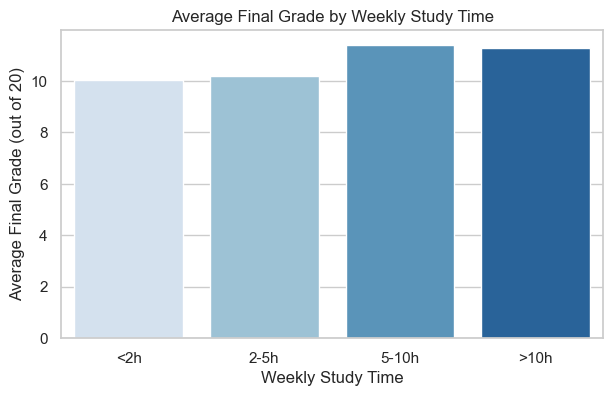

study_band
<2h      10.05
2-5h     10.17
5-10h    11.40
>10h     11.26
Name: G3, dtype: float64
Students per group: {'<2h': 105, '2-5h': 198, '5-10h': 65, '>10h': 27}
Correlation: 0.1


In [39]:
order = ["<2h", "2-5h", "5-10h", ">10h"]                              # Fixed order so the chart reads from low to high
study_avg = df.groupby("study_band")["G3"].mean().reindex(order)      # Average final grade for each study-time group

plt.figure(figsize=(7, 4))
sns.barplot(
    x=study_avg.index,
    y=study_avg.values,
    palette="Blues"
)
plt.title("Average Final Grade by Weekly Study Time")
plt.xlabel("Weekly Study Time")
plt.ylabel("Average Final Grade (out of 20)")
plt.show()

print(study_avg.round(2))                                             # Print exact averages
print("Students per group:", df["study_band"].value_counts()[order].to_dict())  # Group sizes (important for trust!)
print("Correlation:", round(df["studytime"].corr(df["G3"]), 2))       # Strength of the link, from -1 to +1

**Meaning:** Students who study more than 5 hours a week score about **1 point higher** than those studying under 5 hours. The link is positive but **modest** (correlation about 0.10): studying matters, yet study *time* alone does not decide a grade. Study *quality* is not measured here.

📌 *Correlation guide:* near **+1** = strong positive link, near **0** = almost no link, near **-1** = strong negative link.

### 📊 Insight 3: Do past failures predict future grades?

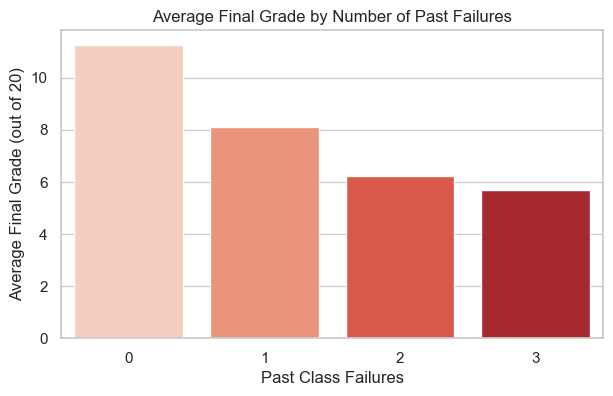

failures
0    11.25
1     8.12
2     6.24
3     5.69
Name: G3, dtype: float64
Correlation: -0.36


In [40]:
fail_avg = df.groupby("failures")["G3"].mean()                        # Average final grade for 0, 1, 2, 3 past failures

plt.figure(figsize=(7, 4))
sns.barplot(
    x=fail_avg.index,
    y=fail_avg.values,
    palette="Reds"
)
plt.title("Average Final Grade by Number of Past Failures")
plt.xlabel("Past Class Failures")
plt.ylabel("Average Final Grade (out of 20)")
plt.show()

print(fail_avg.round(2))                                              # Exact averages
print("Correlation:", round(df["failures"].corr(df["G3"]), 2))        # Strength of the link

**Meaning:** This is the **strongest habit-type signal** in the dataset (correlation about -0.36). Students with no past failures average about 11.3, while those with one failure average about 8.1. A school can use this to offer **extra support early** to students who have struggled before.

### 📊 Insight 4: Absences and a hidden data problem 🕵️

In [41]:
print("Correlation (all students):", round(df["absences"].corr(df["G3"]), 2))  # Link between absences and final grade, everyone included

print("Absences of students with grade 0:", df.loc[df["G3"] == 0, "absences"].unique())  # What absence values do the zero-grade students have?

Correlation (all students): 0.03
Absences of students with grade 0: [0]


Two surprises:
1. The overall correlation is almost **zero** (0.03), which seems odd. More absences should hurt grades.
2. **Every** student with a final grade of 0 has exactly **0 absences**. These students probably left the course or never sat the exam, so their attendance was never recorded. Their records are **not typical**, and they distort the picture.

A good analyst investigates surprises instead of ignoring them. Let us compare with and without those students.

Correlation (excluding grade-0 students): -0.21


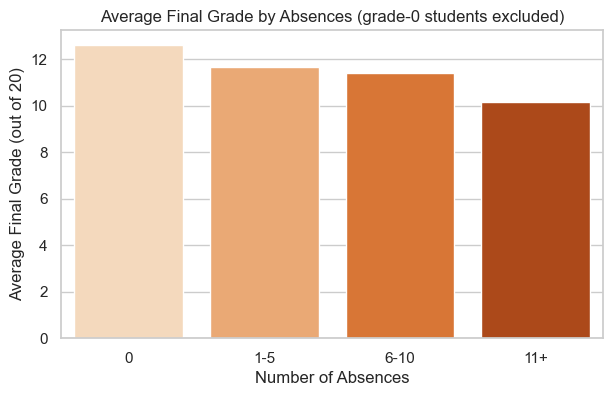

absences
0       12.61
1-5     11.65
6-10    11.40
11+     10.15
Name: G3, dtype: float64


In [42]:
active = df[df["G3"] > 0]                                             # Keep only students with a recorded final grade above 0
print("Correlation (excluding grade-0 students):", round(active["absences"].corr(active["G3"]), 2))  # Recalculate the link

groups = pd.cut(active["absences"], bins=[-1, 0, 5, 10, 100],
                labels=["0", "1-5", "6-10", "11+"])                   # Group students by number of absences
abs_avg = active.groupby(groups, observed=True)["G3"].mean()          # Average grade for each absence group

plt.figure(figsize=(7, 4))
sns.barplot(
    x=abs_avg.index,
    y=abs_avg.values,
    palette="Oranges"
)
plt.title("Average Final Grade by Absences (grade-0 students excluded)")
plt.xlabel("Number of Absences")
plt.ylabel("Average Final Grade (out of 20)")
plt.show()
print(abs_avg.round(2))                                               # Exact averages

**Meaning:** After separating the unusual records, the expected pattern appears: **more absences go with lower grades** (correlation about -0.21; the 11+ group averages around 10 versus about 12.6 for no absences).  
🎯 **Lesson:** the same data can tell different stories depending on how carefully you clean it. This is why data cleaning is a core skill.

### 📊 Insight 5: Ambition, internet and relationships

Wants higher education -> {'no': 6.8, 'yes': 10.61} | group sizes: {'yes': 375, 'no': 20}
Internet at home -> {'no': 9.41, 'yes': 10.62} | group sizes: {'yes': 329, 'no': 66}
In a relationship -> {'no': 10.84, 'yes': 9.58} | group sizes: {'no': 263, 'yes': 132}


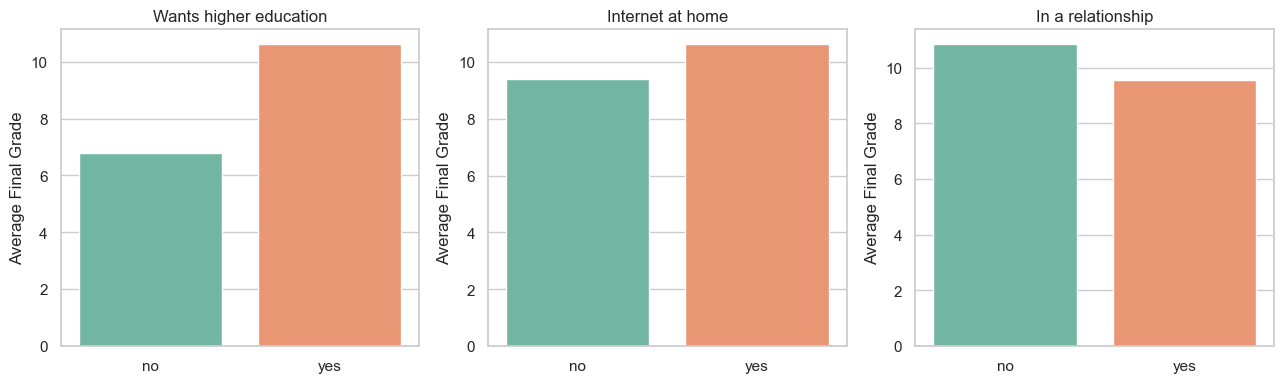

In [43]:
fig, axes = plt.subplots(1, 3, figsize=(13, 4))                       # Three charts side by side
items = [("higher", "Wants higher education"),
         ("internet", "Internet at home"),
         ("romantic", "In a relationship")]                           # (column name, chart title) pairs

for ax, (col, title) in zip(axes, items):                             # Loop over the three charts and their positions
    means = df.groupby(col)["G3"].mean()                              # Average grade for "no" and "yes"
    sns.barplot(
        x=means.index,
        y=means.values,
        palette="Set2",
        ax=ax
    )
    ax.set_title(title)                                               # Chart title
    ax.set_xlabel("")                                                 # No x-axis label needed
    ax.set_ylabel("Average Final Grade")                              # y-axis label
    print(title, "->", means.round(2).to_dict(),
          "| group sizes:", df[col].value_counts().to_dict())         # Print averages AND group sizes

plt.tight_layout()                                                    # Stop charts from overlapping
plt.show()

**Meaning:**
- **Wants higher education:** students who do average about **3.8 points more** (10.6 vs 6.8). ⚠️ Only **20 students** said "no", so treat this carefully: small groups can mislead.
- **Internet at home:** about 1.2 points higher on average, which suggests access to online learning resources can help.
- **Relationship:** students in a relationship average about 1.3 points lower. This is only a **link**, not proof that relationships lower grades (for example, time or other factors could play a role).

### 📊 Insight 6: Social life and family background

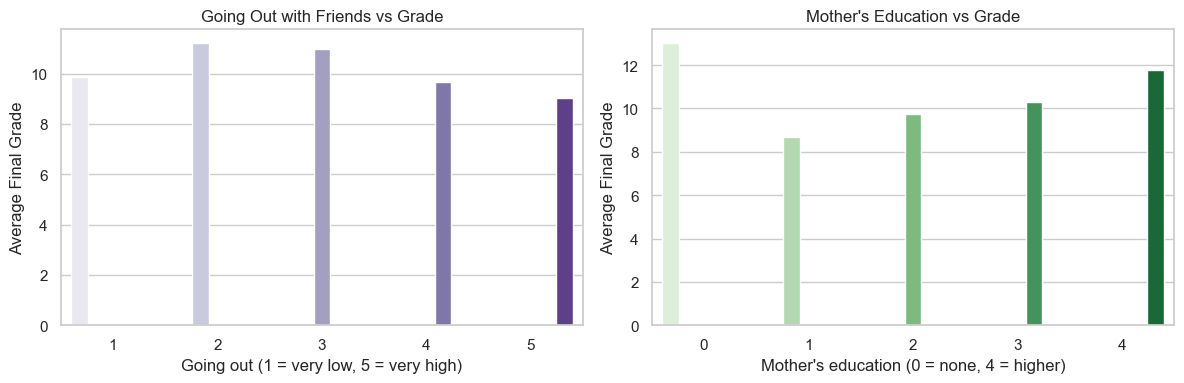

Students per mother's-education level: {0: 3, 1: 59, 2: 103, 3: 99, 4: 131}


In [44]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))                       # Two charts side by side

go_avg = df.groupby("goout")["G3"].mean()                             # Average grade for each "going out" level (1 to 5)
sns.barplot(
    x=go_avg.index,
    y=go_avg.values,
    hue=go_avg.index,
    palette="Purples",
    ax=axes[0]
)

if axes[0].legend_ is not None:
    axes[0].legend_.remove()
axes[0].set_title("Going Out with Friends vs Grade")
axes[0].set_xlabel("Going out (1 = very low, 5 = very high)")
axes[0].set_ylabel("Average Final Grade")

med_avg = df.groupby("Medu")["G3"].mean()                             # Average grade for each mother's education level (0 to 4)
sns.barplot(
    x=med_avg.index,
    y=med_avg.values,
    hue=med_avg.index,
    palette="Greens",
    ax=axes[1]
)

if axes[1].legend_ is not None:
    axes[1].legend_.remove()
axes[1].set_title("Mother's Education vs Grade")
axes[1].set_xlabel("Mother's education (0 = none, 4 = higher)")
axes[1].set_ylabel("Average Final Grade")

plt.tight_layout()
plt.show()
print("Students per mother's-education level:", df["Medu"].value_counts().sort_index().to_dict())  # Group sizes

**Meaning:** Students who go out **a lot** (levels 4 and 5) average lower grades than those with moderate social lives (levels 2 and 3). A balanced social life seems healthier than none or too much. Higher family education also tends to go with higher grades, which is a reminder that **background and support matter**, and why schools should offer help to all students equally.  
(Level 0 for mother's education has very few students, so ignore that single bar.)

### 📊 Insight 7: The big picture, a correlation heatmap

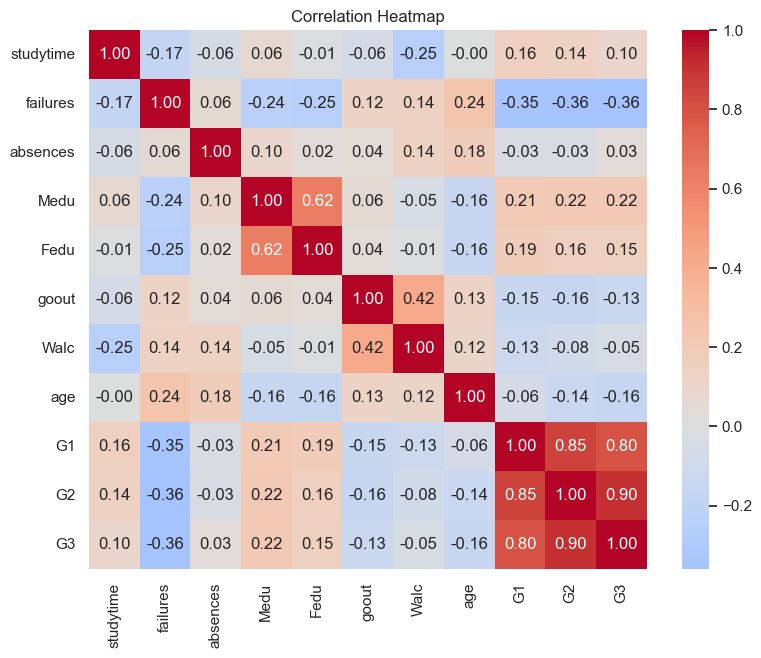

In [45]:
num_cols = ["studytime", "failures", "absences", "Medu", "Fedu",
            "goout", "Walc", "age", "G1", "G2", "G3"]                 # Numeric columns to compare
plt.figure(figsize=(9, 7))
sns.heatmap(df[num_cols].corr(), annot=True, fmt=".2f",
            cmap="coolwarm", center=0)                                # Colour grid: red = positive link, blue = negative link
plt.title("Correlation Heatmap")
plt.show()

**How to read it:** look at the **G3** row (or column).
- **G2 (0.90) and G1 (0.80)** are by far the strongest: students who did well in earlier periods usually keep doing well.
- **failures (-0.36)**, **age (-0.16)** and **Medu (0.22)** come next.
- Habits like study time or alcohol have **small** links on their own.

⚠️ **Correlation is not causation.** Two things moving together does not prove one causes the other.

## 6️⃣ Predictive Analytics (Simple Machine Learning)
**Goal:** estimate a student's final grade (`G3`), so a school can spot students who may need help **before** the final exam.

We use **Linear Regression**, which finds the best "formula" connecting inputs to the output. We test three scenarios to see **what information really helps**:

- **A:** background and habits only (no grades)  
- **B:** A + the **first-period grade (G1)**  
- **C:** A + **G1 and G2**

In [46]:
base = ["studytime", "failures", "absences", "Medu", "Fedu",
        "goout", "higher_n", "internet_n", "age", "Walc"]             # Habit and background inputs used in every scenario

scenarios = {
    "A: Habits & background only": base,                              # Scenario A inputs
    "B: + first-period grade (G1)": base + ["G1"],                    # Scenario B inputs
    "C: + G1 and G2": base + ["G1", "G2"],                            # Scenario C inputs
}

results = []                                                          # Empty list to store each scenario's scores
for name, features in scenarios.items():                              # Repeat the steps below for each scenario
    X = df[features]                                                  # Inputs (X): the information we know in advance
    y = df["G3"]                                                      # Output (y): the final grade we want to predict
    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.2, random_state=42)                         # 80% for learning, 20% hidden for a fair test
    model = LinearRegression().fit(X_train, y_train)                  # Create the model and teach it with training data
    pred = model.predict(X_test)                                      # Predict grades for the unseen students
    results.append({"Scenario": name,
                    "R² (1 = perfect)": round(r2_score(y_test, pred), 2),
                    "Average error (grade points)": round(mean_absolute_error(y_test, pred), 2)})  # Save both scores

results_df = pd.DataFrame(results)                                    # Turn the results into a table
results_df

,Scenario,R² (1 = perfect),Average error (grade points)
0,A: Habits & background only,0.07,3.51
1,B: + first-period grade (G1),0.69,1.93
2,C: + G1 and G2,0.77,1.39


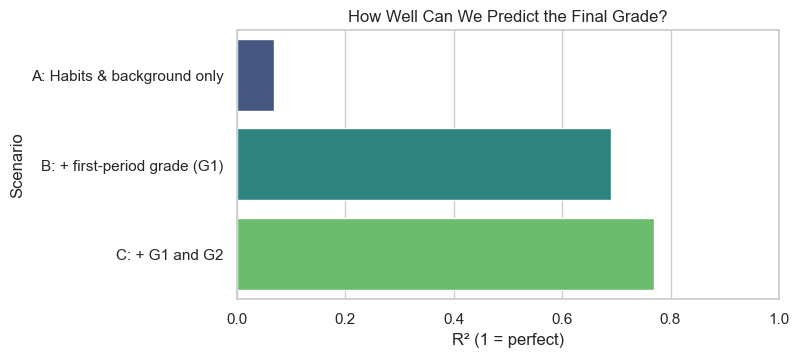

In [48]:
plt.figure(figsize=(7, 3.5))
ax = sns.barplot(
    data=results_df,
    y="Scenario",
    x="R² (1 = perfect)",
    hue="Scenario",
    palette="viridis",
    dodge=False
)
if ax.legend_ is not None:
    ax.legend_.remove()
plt.title("How Well Can We Predict the Final Grade?")
plt.xlim(0, 1)                                                        # R² usually lies between 0 and 1
plt.show()

**How to read the result:**
- **R²** shows how much of the variation in grades the model explains (0 = nothing, 1 = everything).
- **Average error** is the typical mistake in grade points (out of 20).

**Key lessons**
1. **Scenario A is weak** (R² near 0.07). Habits and background alone predict grades poorly, because many hidden factors (motivation, teaching quality, health) are not in the data.
2. **Adding past grades improves predictions dramatically.** The first-period grade (G1) alone lifts R² from about 0.07 to about 0.69 (average error drops from about 3.5 to about 1.9 points); adding G2 reaches about 0.77. Past performance is the best predictor of future performance.
3. **Real-life trade-off:** Scenario C is the most accurate but arrives late, when little time is left to help. Scenario B (after the first period) is the best **early-warning** balance.

⚠️ The model is a **screening tool, not a verdict**. It should trigger a supportive conversation, never a label on a student.

In [49]:
new_student = pd.DataFrame({"studytime": [3], "failures": [0], "absences": [2], "Medu": [3], "Fedu": [3],
                            "goout": [3], "higher_n": [1], "internet_n": [1], "age": [16], "Walc": [2],
                            "G1": [12]})                              # Details of one imaginary student (with first-period grade 12)

features_B = base + ["G1"]                                            # Inputs used in scenario B
model_B = LinearRegression().fit(df[features_B], df["G3"])            # Train model B on ALL students this time
print("Predicted final grade:", round(model_B.predict(new_student[features_B])[0], 1), "/ 20")  # Predict and print the grade

Predicted final grade: 11.6 / 20


## 7️⃣ Key Findings (Insights Summary)

| # | Finding from real data | What can a student do? | What can a school do? |
|---|---|---|---|
| 1 | Past failures are linked with much lower grades | Ask for help early, do not wait | Early tutoring for students with failures |
| 2 | Studying 5+ hours a week is linked with about 1 point higher grades | Build a steady weekly routine | Teach study skills in first year |
| 3 | More absences go with lower grades (once unusual records are separated) | Attend regularly | Alert mentors when attendance drops |
| 4 | Heavy social life (very high "going out") is linked with lower grades | Aim for balance, not zero social life | Offer time-management workshops |
| 5 | Internet access and ambition are linked with higher grades | Use online learning resources | Provide access to computers and Wi-Fi |
| 6 | Early grades predict final grades very well | Take the first test seriously | Use first-period results for early warning |

## 8️⃣ Where Is This Used in Real Life?

- 🏫 **Universities:** early-warning dashboards for at-risk students; planning tutoring and mentoring.
- 📱 **Learning apps (Duolingo, Khan Academy):** track habits and personalise lessons.
- 🧑‍💼 **Placement cells:** find which skills lead to jobs.
- 🏥 **Student wellbeing:** study stress, sleep and social patterns guide counselling programmes.
- 💰 **Scholarships and support:** decide who needs help using evidence.

## 9️⃣ Limitations (Be a Responsible Analyst)
1. The data comes from **two Portuguese schools in one subject (Mathematics)**, so results may differ elsewhere.
2. **Correlation is not causation.**
3. Self-reported answers (study time, alcohol use) may be inaccurate.
4. Some groups are small (for example only 20 students do not want higher education), so conclusions about them are shaky.
5. **Privacy and fairness:** never use such models to label or punish students. Protect personal data.

## 🔟 Practice Tasks
1. Compare average `G3` for **male vs female** students (`df.groupby("sex")`). Is the gap large?
2. Make a chart of `G3` by `Walc` (weekend alcohol use). What do you notice?
3. Create a column `age_group` with `pd.cut` and compare grades by age.
4. Repeat the analysis with `student-por.csv` (the **Portuguese language** course) from the same UCI source. Do the same patterns appear?
5. Add `G2` to a model for pass/fail only and discuss: is it still "early" warning?

---
**Data source:** P. Cortez and A. Silva, *Using Data Mining to Predict Secondary School Student Performance*, 2008. Dataset: *Student Performance*, UCI Machine Learning Repository.

*Congratulations! You completed a full data analytics workflow: Collect → Clean → Explore → Analyse → Predict → Decide.* 🎉